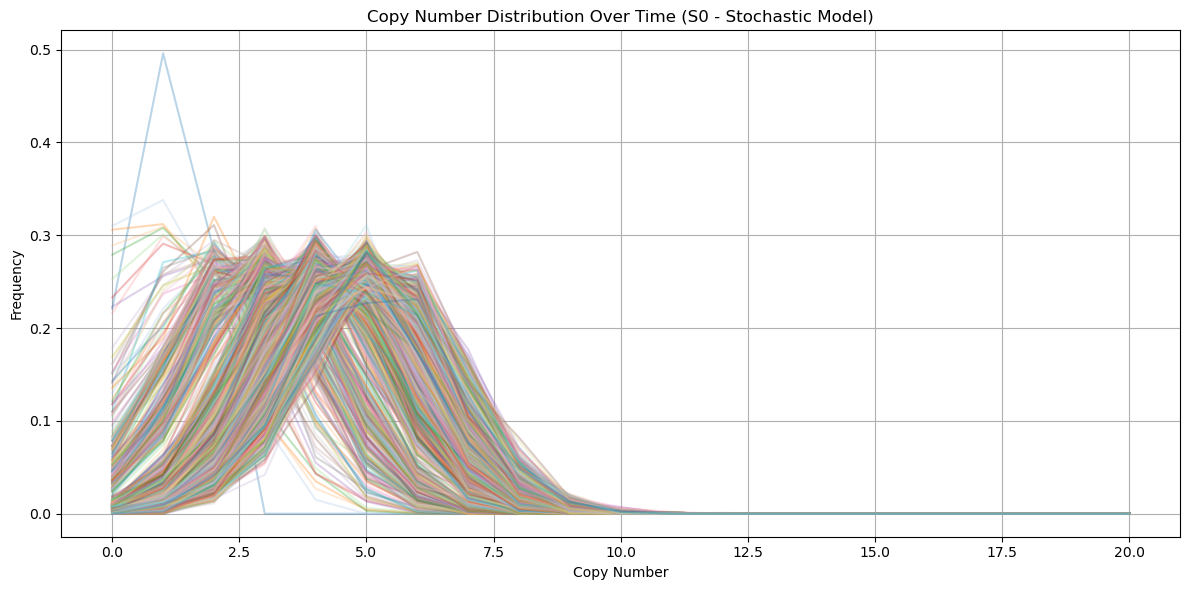

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

# === PARAMS ===
N = 1000              # Population size
generations = 1000     # Number of generations
max_copy = 20        # Max allowed copy number (for visualization safety)
init_dist = [0.2, 0.5, 0.3]  # Initial copy number distribution (for 0,1,2 copies)

# === TOY RECOMBINATION FUNCTION ===
def recombine(c1, c2):
    """
    Simple recombination: child gets average of parents + noise
    Enforces integer copy number
    """
    base = (c1 + c2) / 2
    noise = np.random.normal(loc=0.0, scale=1.0)
    new_copy = int(round(base + noise))
    return max(0, min(new_copy, max_copy))  # Bound the result

# === INITIALIZE POPULATION ===
def init_population(N, dist):
    states = np.arange(len(dist))
    return list(np.random.choice(states, size=N, p=dist))

# === SIMULATE ===
def simulate_S0_population(N, generations, init_dist):
    population = init_population(N, init_dist)
    history = [population.copy()]
    
    for gen in range(generations):
        next_gen = []
        for _ in range(N):
            p1, p2 = np.random.choice(population, 2)
            child = recombine(p1, p2)
            next_gen.append(child)
        population = next_gen
        history.append(population.copy())
    
    return history

# === RUN ===
history = simulate_S0_population(N, generations, init_dist)

# === PLOT ===
def plot_copy_number_dynamics(history, max_copy=20):
    plt.figure(figsize=(12, 6))
    cmap = plt.get_cmap("tab20")

    for gen, pop in enumerate(history):
        counts = Counter(pop)
        y = [counts.get(i, 0) / len(pop) for i in range(max_copy + 1)]
        plt.plot(range(max_copy + 1), y, label=f"Gen {gen}", alpha=0.3, color=cmap(gen % 20))
    
    plt.xlabel("Copy Number")
    plt.ylabel("Frequency")
    plt.title("Copy Number Distribution Over Time (S0 - Stochastic Model)")
    plt.grid(True)
    plt.tight_layout()
    plt.show()

plot_copy_number_dynamics(history)


In [2]:
def sample_child_from_parents(y1, y2, T):
    """
    Sample a child's copy number from parent y1 and y2 using the T tensor.
    y1, y2: parent copy numbers (positive integers, 1-based)
    T: recombination tensor of shape [n, n, n]
    Returns: child copy number (int)
    """
    y1_idx = y1 - 1
    y2_idx = y2 - 1
    probs = T[:, y1_idx, y2_idx]  # shape (n,)
    if probs.sum() == 0:
        raise ValueError(f"No valid recombination outcome for ({y1}, {y2})")
    probs /= probs.sum()  # Normalize in case of float rounding
    child_copy = np.random.choice(np.arange(1, len(probs)+1), p=probs)
    return child_copy
def simulate_S0_real_pop(N, generations, init_dist, T):
    """
    Simulates real population evolution under neutral model using recombination tensor T.
    - N: population size
    - generations: number of generations to simulate
    - init_dist: array-like, probabilities for initial copy numbers 1..n
    - T: trapezoid recombination tensor
    Returns: list of populations over time, each is a list of copy numbers
    """
    n = T.shape[0]
    # Initialize population
    init_states = np.arange(1, n + 1)
    population = list(np.random.choice(init_states, size=N, p=init_dist))
    history = [population.copy()]
    
    for gen in range(generations):
        next_gen = []
        for _ in range(N):
            p1 = np.random.choice(population)
            p2 = np.random.choice(population)
            child = sample_child_from_parents(p1, p2, T)
            next_gen.append(child)
        population = next_gen
        history.append(population.copy())
    
    return history
def plot_copy_distribution(history, max_copy=None):
    import matplotlib.pyplot as plt
    from collections import Counter

    max_copy = max_copy or max(max(gen) for gen in history)
    plt.figure(figsize=(12, 6))
    for t, pop in enumerate(history):
        counts = Counter(pop)
        freqs = [counts.get(k, 0) / len(pop) for k in range(1, max_copy+1)]
        plt.plot(range(1, max_copy+1), freqs, label=f"Gen {t}", alpha=0.3)
    plt.xlabel("Copy Number")
    plt.ylabel("Frequency")
    plt.title("Stochastic Simulation of Copy Number Evolution (S0)")
    plt.grid(True)
    plt.tight_layout()
    plt.show()
